# Fraud Detection in Highly Imbalanced Digital Banking Transactions

Compares Logistic Regression, Random Forest and Isolation Forest on the
Kaggle Credit Card Fraud dataset (mlg-ulb/creditcardfraud).

What this notebook does, in order:
  1. Loads creditcard.csv (local file, Kaggle download, or Colab upload).
  2. Runs a Mann-Whitney U test on each of the 30 features (Bonferroni
     corrected) and reports the rank-biserial effect size.
  3. Makes a stratified 80/20 train/test split. The test set is not touched
     until the final evaluation.
  4. For Logistic Regression and Random Forest, compares class weighting with
     SMOTE. Scaling and SMOTE sit inside the pipeline, so they are fitted on
     the training part of each cross-validation fold only (no leakage).
  5. Picks each model's decision threshold from out-of-fold predictions
     (maximum F1), then applies it once to the test set.
  6. Trains Isolation Forest without labels as an unsupervised baseline.
  7. Saves every figure and a results file to ./outputs and zips them.

Run everything with **Runtime > Run all**.

## Setup

In [ ]:
import glob
import json
import os
import subprocess
import sys
import time
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import mannwhitneyu
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline
except ImportError:  # not needed in Colab, where imbalanced-learn is preinstalled
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline

## Settings

In [ ]:
SEED = 42
TEST_SIZE = 0.20
N_FOLDS = 5
RF_TREES = 200
RF_SMOTE_MAX_DEPTH = 10      # depth limit used for the SMOTE Random Forest
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, SECONDARY, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": AXIS, "axes.labelcolor": SECONDARY,
    "xtick.color": SECONDARY, "ytick.color": SECONDARY, "text.color": INK,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 200,
})

LOG = []                     # everything printed here also goes to results.txt
RESULTS = {}                 # machine-readable copy, saved as results.json


def say(text=""):
    print(text)
    LOG.append(str(text))


def save_fig(fig, name):
    path = os.path.join(OUT_DIR, name)
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"  saved {path}")


def clean_axes(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)
    if grid_axis:
        getattr(ax, f"{grid_axis}axis").grid(True, color=GRID, lw=0.8, zorder=0)
        ax.set_axisbelow(True)

## 1. Load the data

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Downloaded from Kaggle to /kaggle/input/creditcardfraud
1. DATASET
Rows: 284,807   Features: 30   Missing values: 0
Fraud: 492 (0.173%)   Legitimate: 284,315


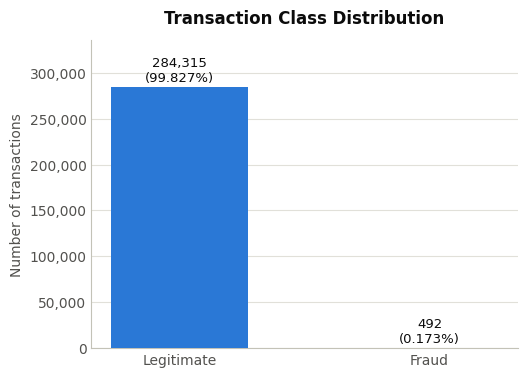

  saved outputs/class_distribution.png


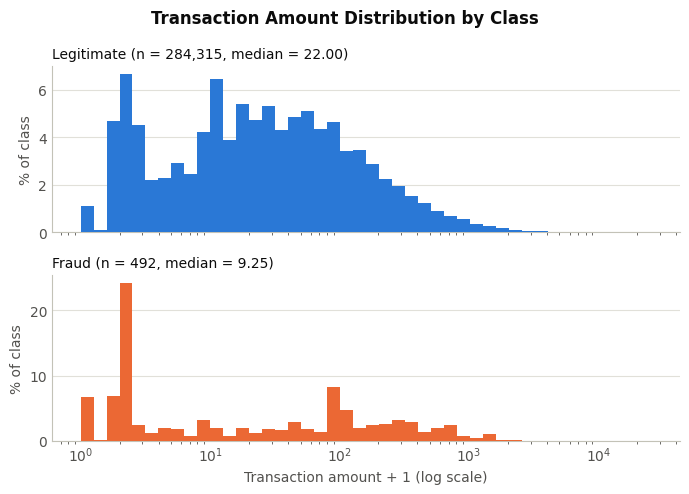

  saved outputs/amount_distribution.png


In [ ]:
def load_data():
    candidates = [os.environ.get("DATA_PATH", ""), "creditcard.csv", "/content/creditcard.csv"]
    candidates += glob.glob("/content/**/creditcard.csv", recursive=True)
    for path in candidates:
        if path and os.path.exists(path):
            print(f"Loading {path}")
            return pd.read_csv(path)
    try:
        import kagglehub
        folder = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
        print(f"Downloaded from Kaggle to {folder}")
        return pd.read_csv(os.path.join(folder, "creditcard.csv"))
    except Exception as err:
        print(f"Kaggle download did not work ({err}).")
    try:
        from google.colab import files
        print("Please upload creditcard.csv (from kaggle.com/datasets/mlg-ulb/creditcardfraud)")
        uploaded = files.upload()
        return pd.read_csv(next(iter(uploaded)))
    except Exception:
        raise SystemExit("creditcard.csv not found. Put it next to this script and run again.")


df = load_data()
FEATURES = [c for c in df.columns if c != "Class"]
n_total, n_fraud = len(df), int(df["Class"].sum())

say("=" * 70)
say("1. DATASET")
say("=" * 70)
say(f"Rows: {n_total:,}   Features: {len(FEATURES)}   Missing values: {int(df.isna().sum().sum())}")
say(f"Fraud: {n_fraud:,} ({n_fraud / n_total:.3%})   Legitimate: {n_total - n_fraud:,}")
if n_total != 284_807:
    say("NOTE: this is not the full 284,807-row dataset.")
RESULTS["dataset"] = {"rows": n_total, "fraud": n_fraud, "fraud_rate": n_fraud / n_total}

# Figure: class distribution
fig, ax = plt.subplots(figsize=(5.5, 4))
counts = [n_total - n_fraud, n_fraud]
bars = ax.bar(["Legitimate", "Fraud"], counts, color=[BLUE, ORANGE], width=0.55, zorder=3)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + n_total * 0.01,
            f"{count:,}\n({count / n_total:.3%})", ha="center", va="bottom", fontsize=9.5)
ax.set_ylim(0, max(counts) * 1.18)
ax.set_ylabel("Number of transactions")
ax.set_title("Transaction Class Distribution", fontweight="bold", pad=12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
clean_axes(ax)
save_fig(fig, "class_distribution.png")

# Figure: transaction amount by class (log-spaced bins, share of each class)
fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
bins = np.logspace(0, np.log10(df["Amount"].max() + 2), 45)
for ax, label, colour in zip(axes, [0, 1], [BLUE, ORANGE]):
    amounts = df.loc[df["Class"] == label, "Amount"] + 1
    ax.hist(amounts, bins=bins, weights=np.full(len(amounts), 100 / len(amounts)), color=colour, zorder=3)
    name = "Legitimate" if label == 0 else "Fraud"
    ax.set_title(f"{name} (n = {len(amounts):,}, median = {amounts.median() - 1:,.2f})",
                 fontsize=10, loc="left")
    ax.set_ylabel("% of class")
    ax.set_xscale("log")
    clean_axes(ax)
axes[1].set_xlabel("Transaction amount + 1 (log scale)")
fig.suptitle("Transaction Amount Distribution by Class", fontweight="bold")
fig.tight_layout()
save_fig(fig, "amount_distribution.png")

## 2. Hypothesis tests: does each feature differ between the two classes?

In [ ]:
fraud_rows, legit_rows = df[df["Class"] == 1], df[df["Class"] == 0]
alpha = 0.05 / len(FEATURES)                       # Bonferroni correction
tests = []
for feature in FEATURES:
    u_stat, p_value = mannwhitneyu(fraud_rows[feature], legit_rows[feature], alternative="two-sided")
    # Rank-biserial correlation: positive = fraud tends to be higher.
    effect = 2 * u_stat / (len(fraud_rows) * len(legit_rows)) - 1
    tests.append({"feature": feature, "p_value": float(p_value), "r": float(effect),
                  "significant": bool(p_value < alpha)})
tests_df = pd.DataFrame(tests).sort_values("r", key=np.abs, ascending=False).reset_index(drop=True)
n_significant = int(tests_df["significant"].sum())

say()
say("=" * 70)
say("2. MANN-WHITNEY U TESTS (fraud vs legitimate, all rows)")
say("=" * 70)
say(f"Bonferroni alpha = 0.05 / {len(FEATURES)} = {alpha:.5f}")
say(f"Features significant after correction: {n_significant} of {len(FEATURES)}")
say("Not significant: " + (", ".join(tests_df.loc[~tests_df["significant"], "feature"]) or "none"))
say()
say("All features, sorted by effect size |r| (rank-biserial; positive = higher in fraud):")
for row in tests_df.itertuples():
    say(f"  {row.feature:<7} r = {row.r:+.3f}   p = {row.p_value:.2e}   "
        f"{'significant' if row.significant else 'not significant'}")
RESULTS["mann_whitney"] = {"alpha": alpha, "n_significant": n_significant, "tests": tests_df.to_dict("records")}


2. MANN-WHITNEY U TESTS (fraud vs legitimate, all rows)
Bonferroni alpha = 0.05 / 30 = 0.00167
Features significant after correction: 24 of 30
Not significant: V26, V23, V25, V13, V15, V22

All features, sorted by effect size |r| (rank-biserial; positive = higher in fraud):
  V14     r = -0.898   p = 1.47e-260   significant
  V4      r = +0.877   p = 3.63e-248   significant
  V12     r = -0.874   p = 8.42e-247   significant
  V11     r = +0.836   p = 4.91e-226   significant
  V10     r = -0.828   p = 9.61e-222   significant
  V3      r = -0.824   p = 1.21e-219   significant
  V2      r = +0.710   p = 1.65e-163   significant
  V16     r = -0.694   p = 1.81e-156   significant
  V9      r = -0.688   p = 8.94e-154   significant
  V7      r = -0.672   p = 1.46e-146   significant
  V17     r = -0.616   p = 9.22e-124   significant
  V1      r = -0.590   p = 1.74e-113   significant
  V6      r = -0.534   p = 2.23e-93   significant
  V21     r = +0.493   p = 8.67e-80   significant
  V18     r 

## 3. Train/test split and preprocessing

In [ ]:
X, y = df[FEATURES], df["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)


def make_preprocessor():
    # V1-V28 are already PCA-scaled, so only Time and Amount are standardised.
    return ColumnTransformer([("scale", StandardScaler(), ["Time", "Amount"])],
                             remainder="passthrough", verbose_feature_names_out=False)


smote_check = SMOTE(random_state=SEED).fit_resample(make_preprocessor().fit_transform(X_train), y_train)[1]

say()
say("=" * 70)
say("3. TRAIN/TEST SPLIT")
say("=" * 70)
say(f"Training set size: {len(y_train):,} ({int(y_train.sum())} fraud)")
say(f"Testing set size:  {len(y_test):,} ({int(y_test.sum())} fraud)")
say(f"After SMOTE - Training set: {len(smote_check):,} ({int(smote_check.sum()):,} fraud)")
say("(SMOTE is refitted inside every cross-validation fold; the test set is never resampled.)")
RESULTS["split"] = {"train_rows": len(y_train), "train_fraud": int(y_train.sum()),
                    "test_rows": len(y_test), "test_fraud": int(y_test.sum()),
                    "smote_train_rows": len(smote_check), "smote_train_fraud": int(smote_check.sum())}


3. TRAIN/TEST SPLIT
Training set size: 227,845 (394 fraud)
Testing set size:  56,962 (98 fraud)
After SMOTE - Training set: 454,902 (227,451 fraud)
(SMOTE is refitted inside every cross-validation fold; the test set is never resampled.)


## 4. Supervised models: class weighting vs SMOTE

In [ ]:
MODELS = {
    "LR class-weighted": lambda: Pipeline([
        ("prep", make_preprocessor()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))]),
    "LR SMOTE": lambda: Pipeline([
        ("prep", make_preprocessor()),
        ("smote", SMOTE(random_state=SEED)),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]),
    "RF class-weighted": lambda: Pipeline([
        ("prep", make_preprocessor()),
        ("clf", RandomForestClassifier(n_estimators=RF_TREES, class_weight="balanced",
                                       n_jobs=-1, random_state=SEED))]),
    "RF SMOTE": lambda: Pipeline([
        ("prep", make_preprocessor()),
        ("smote", SMOTE(random_state=SEED)),
        ("clf", RandomForestClassifier(n_estimators=RF_TREES, max_depth=RF_SMOTE_MAX_DEPTH,
                                       n_jobs=-1, random_state=SEED))]),
}


def best_f1_threshold(y_true, scores):
    """Threshold that maximises F1. Predict fraud when score >= threshold."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    best = int(np.argmax(f1))
    return float(thresholds[best]), float(f1[best])


def evaluate(y_true, predictions):
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
            "precision": float(precision), "recall": float(recall), "f1": float(f1)}


def describe(label, m):
    return (f"  {label:<26} caught {m['tp']:>3} of {m['tp'] + m['fn']} fraud, {m['fp']:>5} false alarms | "
            f"precision {m['precision']:.1%}  recall {m['recall']:.1%}  F1 {m['f1']:.3f}")


say()
say("=" * 70)
say("4. SUPERVISED MODELS")
say("=" * 70)
folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
supervised, test_scores, fitted = {}, {}, {}

for name, make_model in MODELS.items():
    started = time.time()
    print(f"\n{name}: cross-validating ...")
    out_of_fold = np.zeros(len(y_train))
    fold_pr_auc = []
    for k, (train_idx, valid_idx) in enumerate(folds.split(X_train, y_train), start=1):
        model = make_model().fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        out_of_fold[valid_idx] = model.predict_proba(X_train.iloc[valid_idx])[:, 1]
        fold_pr_auc.append(average_precision_score(y_train.iloc[valid_idx], out_of_fold[valid_idx]))
        print(f"  fold {k}/{N_FOLDS}  PR-AUC {fold_pr_auc[-1]:.3f}  ({time.time() - started:.0f}s elapsed)")

    threshold, cv_f1 = best_f1_threshold(y_train, out_of_fold)

    print("  fitting on the full training set ...")
    final_model = make_model().fit(X_train, y_train)
    probabilities = final_model.predict_proba(X_test)[:, 1]
    fitted[name], test_scores[name] = final_model, probabilities

    result = {
        "cv_pr_auc_mean": float(np.mean(fold_pr_auc)), "cv_pr_auc_std": float(np.std(fold_pr_auc)),
        "cv_pr_auc_folds": [float(v) for v in fold_pr_auc],
        "tuned_threshold": threshold, "cv_f1_at_tuned_threshold": cv_f1,
        "test_pr_auc": float(average_precision_score(y_test, probabilities)),
        "test_roc_auc": float(roc_auc_score(y_test, probabilities)),
        "test_default_threshold": evaluate(y_test, probabilities >= 0.5),
        "test_tuned_threshold": evaluate(y_test, probabilities >= threshold),
    }
    supervised[name] = result

    say()
    say(f"{name}  (took {time.time() - started:.0f}s)")
    say(f"  Cross-validation PR-AUC: {result['cv_pr_auc_mean']:.3f} +/- {result['cv_pr_auc_std']:.3f}")
    say(f"  Tuned threshold (max F1 on out-of-fold predictions): {threshold:.6f}")
    say(f"  Test PR-AUC: {result['test_pr_auc']:.3f}   Test ROC-AUC: {result['test_roc_auc']:.3f}")
    say(describe("Test @ default 0.5:", result["test_default_threshold"]))
    say(describe("Test @ tuned threshold:", result["test_tuned_threshold"]))

RESULTS["supervised"] = supervised


4. SUPERVISED MODELS

LR class-weighted: cross-validating ...
  fold 1/5  PR-AUC 0.790
  fold 2/5  PR-AUC 0.740
  fold 3/5  PR-AUC 0.668
  fold 4/5  PR-AUC 0.810
  fold 5/5  PR-AUC 0.721
  fitting on the full training set ...

LR class-weighted
  Cross-validation PR-AUC: 0.746 +/- 0.051
  Tuned threshold (max F1 on out-of-fold predictions): 1.000000
  Test PR-AUC: 0.716   Test ROC-AUC: 0.972
  Test @ default 0.5:        caught  90 of 98 fraud,  1386 false alarms | precision 6.1%  recall 91.8%  F1 0.114
  Test @ tuned threshold:    caught  78 of 98 fraud,    16 false alarms | precision 83.0%  recall 79.6%  F1 0.812

LR SMOTE: cross-validating ...
  fold 1/5  PR-AUC 0.797
  fold 2/5  PR-AUC 0.739
  fold 3/5  PR-AUC 0.681
  fold 4/5  PR-AUC 0.802
  fold 5/5  PR-AUC 0.721
  fitting on the full training set ...

LR SMOTE
  Cross-validation PR-AUC: 0.748 +/- 0.046
  Tuned threshold (max F1 on out-of-fold predictions): 1.000000
  Test PR-AUC: 0.725   Test ROC-AUC: 0.970
  Test @ default 0.5:

## 5. Isolation Forest (unsupervised: labels are never shown to the model)

In [ ]:
preprocessor = make_preprocessor().fit(X_train)
contamination = float(y_train.mean())
isolation_forest = IsolationForest(contamination=contamination, random_state=SEED, n_jobs=-1)
isolation_forest.fit(preprocessor.transform(X_train))
X_test_scaled = preprocessor.transform(X_test)
iso_scores = -isolation_forest.score_samples(X_test_scaled)          # higher = more anomalous
iso_result = evaluate(y_test, isolation_forest.predict(X_test_scaled) == -1)
iso_result.update({"contamination": contamination,
                   "test_pr_auc": float(average_precision_score(y_test, iso_scores)),
                   "test_roc_auc": float(roc_auc_score(y_test, iso_scores))})
RESULTS["isolation_forest"] = iso_result

say()
say("=" * 70)
say("5. ISOLATION FOREST")
say("=" * 70)
say(f"  Contamination = training fraud rate = {contamination:.5f}")
say(f"  Test PR-AUC: {iso_result['test_pr_auc']:.3f}   Test ROC-AUC: {iso_result['test_roc_auc']:.3f}")
say(describe("Test:", iso_result))


5. ISOLATION FOREST
  Contamination = training fraud rate = 0.00173
  Test PR-AUC: 0.178   Test ROC-AUC: 0.960
  Test:                      caught  33 of 98 fraud,    76 false alarms | precision 30.3%  recall 33.7%  F1 0.319


## 6. Summary table and figures for the three headline models


6. TABLE 1 - TEST SET PERFORMANCE (n = 56,962; 98 fraud cases)
  Model                Threshold          Precision   Recall      F1   PR-AUC
  Logistic Regression  Tuned (1.0000)         83.0%    79.6%   81.2%    0.716
  Random Forest        Tuned (0.33)           94.3%    83.7%   88.6%    0.864
  Isolation Forest     Contamination          30.3%    33.7%   31.9%    0.178


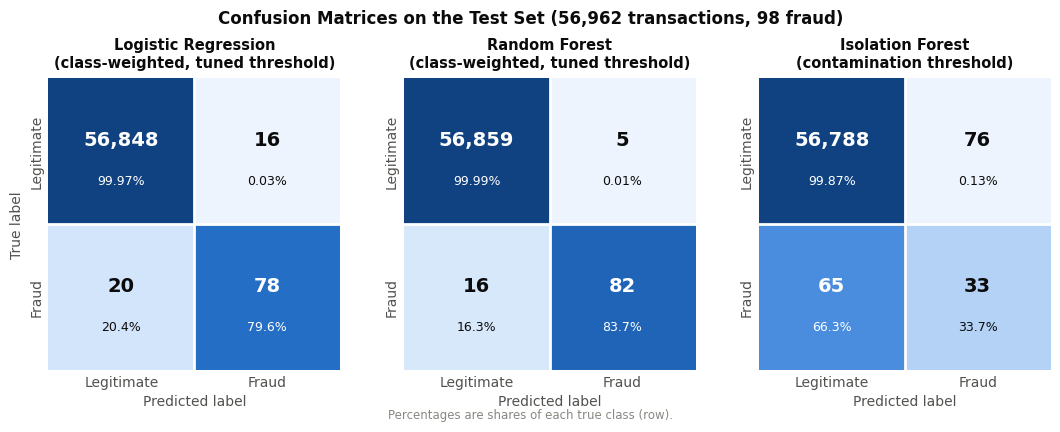

  saved outputs/confusion_matrices.png


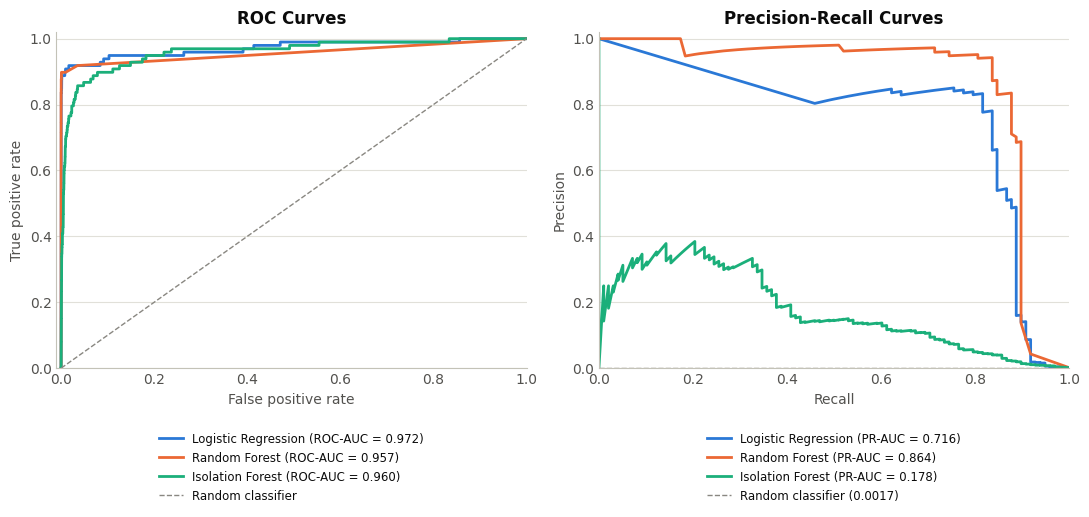

  saved outputs/roc_pr_curves.png


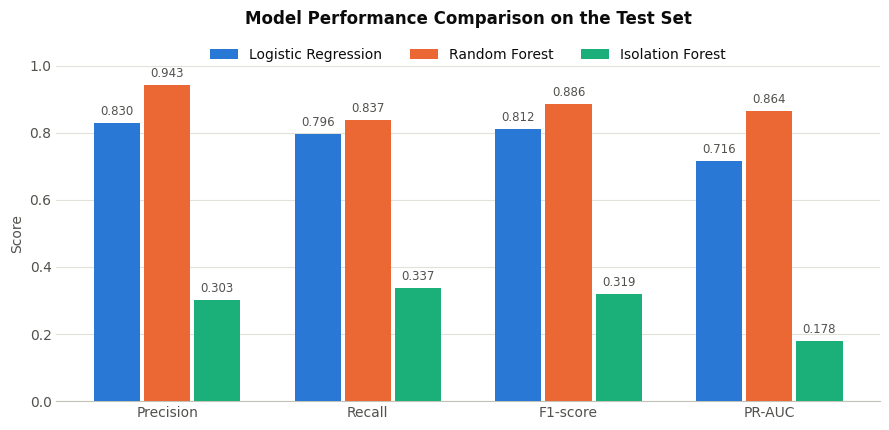

  saved outputs/model_performance.png


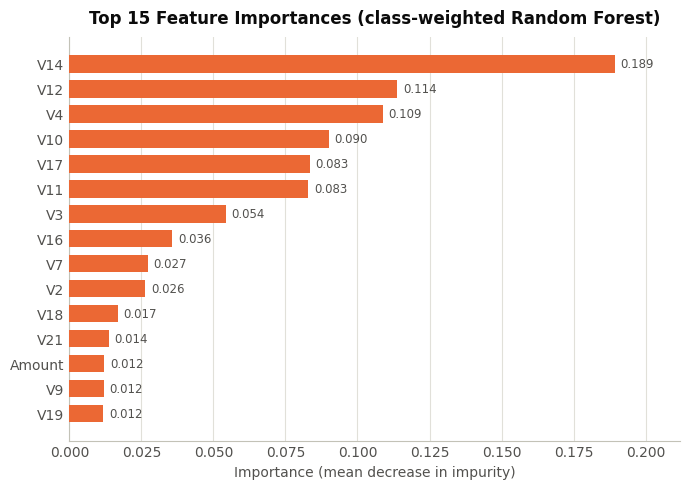

  saved outputs/feature_importances.png

7. RANDOM FOREST FEATURE IMPORTANCES (class-weighted model, top 15)
  V14     0.1892
  V12     0.1139
  V4      0.1088
  V10     0.0900
  V17     0.0834
  V11     0.0830
  V3      0.0542
  V16     0.0358
  V7      0.0272
  V2      0.0264
  V18     0.0167
  V21     0.0136
  Amount  0.0121
  V9      0.0121
  V19     0.0118


In [ ]:
lr, rf = supervised["LR class-weighted"], supervised["RF class-weighted"]
headline = {
    "Logistic Regression": {**lr["test_tuned_threshold"], "pr_auc": lr["test_pr_auc"],
                            "threshold": f"Tuned ({lr['tuned_threshold']:.4f})"},
    "Random Forest": {**rf["test_tuned_threshold"], "pr_auc": rf["test_pr_auc"],
                      "threshold": f"Tuned ({rf['tuned_threshold']:.2f})"},
    "Isolation Forest": {**iso_result, "pr_auc": iso_result["test_pr_auc"], "threshold": "Contamination"},
}
COLOURS = {"Logistic Regression": BLUE, "Random Forest": ORANGE, "Isolation Forest": AQUA}

say()
say("=" * 70)
say(f"6. TABLE 1 - TEST SET PERFORMANCE (n = {len(y_test):,}; {int(y_test.sum())} fraud cases)")
say("=" * 70)
say(f"  {'Model':<21}{'Threshold':<18}{'Precision':>10}{'Recall':>9}{'F1':>8}{'PR-AUC':>9}")
for name, m in headline.items():
    say(f"  {name:<21}{m['threshold']:<18}{m['precision']:>10.1%}{m['recall']:>9.1%}"
        f"{m['f1']:>8.1%}{m['pr_auc']:>9.3f}")

# Figure: confusion matrices
blues = LinearSegmentedColormap.from_list("blues", ["#eef4fd", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"])
subtitles = {"Logistic Regression": "class-weighted, tuned threshold",
             "Random Forest": "class-weighted, tuned threshold",
             "Isolation Forest": "contamination threshold"}
fig, axes = plt.subplots(1, 3, figsize=(11, 4.2))
for ax, (name, m) in zip(axes, headline.items()):
    matrix = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    share = matrix / matrix.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=blues, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            colour = "white" if share[i, j] > 0.55 else INK
            pct = share[i, j] * 100
            ax.text(j, i - 0.08, f"{matrix[i, j]:,}", ha="center", va="center",
                    fontsize=14, fontweight="bold", color=colour)
            ax.text(j, i + 0.2, f"{pct:.2f}%" if pct < 1 or pct > 99 else f"{pct:.1f}%",
                    ha="center", va="center", fontsize=9, color=colour)
    ax.set_xticks([0, 1], ["Legitimate", "Fraud"])
    ax.set_yticks([0, 1], ["Legitimate", "Fraud"], rotation=90, va="center")
    ax.set_xlabel("Predicted label")
    ax.set_title(f"{name}\n({subtitles[name]})", fontsize=10.5, fontweight="bold", pad=8)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([0.5], minor=True)
    ax.set_yticks([0.5], minor=True)
    ax.grid(which="minor", color="white", lw=2)
    ax.tick_params(which="minor", length=0)
axes[0].set_ylabel("True label")
fig.suptitle(f"Confusion Matrices on the Test Set ({len(y_test):,} transactions, {int(y_test.sum())} fraud)",
             fontsize=12, fontweight="bold", y=0.99)
fig.text(0.5, 0.015, "Percentages are shares of each true class (row).", ha="center", fontsize=8.5, color=MUTED)
fig.tight_layout(rect=(0, 0.09, 1, 0.95))
save_fig(fig, "confusion_matrices.png")

# Figure: ROC and precision-recall curves
curve_scores = {"Logistic Regression": test_scores["LR class-weighted"],
                "Random Forest": test_scores["RF class-weighted"],
                "Isolation Forest": iso_scores}
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 5.4))
for name, scores in curve_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ax_roc.plot(fpr, tpr, color=COLOURS[name], lw=2,
                label=f"{name} (ROC-AUC = {roc_auc_score(y_test, scores):.3f})")
    ax_pr.plot(recall, precision, color=COLOURS[name], lw=2,
               label=f"{name} (PR-AUC = {average_precision_score(y_test, scores):.3f})")
ax_roc.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="Random classifier")
ax_pr.axhline(y_test.mean(), color=MUTED, lw=1, ls="--", label=f"Random classifier ({y_test.mean():.4f})")
ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", xlim=(-0.01, 1), ylim=(0, 1.02))
ax_pr.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
ax_roc.set_title("ROC Curves", fontweight="bold")
ax_pr.set_title("Precision-Recall Curves", fontweight="bold")
for ax in (ax_roc, ax_pr):
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=8.5)
    clean_axes(ax)
fig.tight_layout()
save_fig(fig, "roc_pr_curves.png")

# Figure: model performance comparison
metric_names = ["Precision", "Recall", "F1-score", "PR-AUC"]
fig, ax = plt.subplots(figsize=(9, 4.4))
positions, width = np.arange(len(metric_names)), 0.25
for k, (name, m) in enumerate(headline.items()):
    values = [m["precision"], m["recall"], m["f1"], m["pr_auc"]]
    ax.bar(positions + (k - 1) * width, values, width * 0.92, color=COLOURS[name], label=name, zorder=3)
    for x_pos, value in zip(positions + (k - 1) * width, values):
        ax.text(x_pos, value + 0.015, f"{value:.3f}", ha="center", va="bottom", fontsize=8.5, color=SECONDARY)
ax.set_xticks(positions, metric_names)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
clean_axes(ax)
ax.spines["left"].set_visible(False)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.09))
ax.set_title("Model Performance Comparison on the Test Set", fontsize=12, fontweight="bold", pad=30)
fig.tight_layout()
save_fig(fig, "model_performance.png")

# Figure: Random Forest feature importances (final class-weighted model)
forest = fitted["RF class-weighted"]
importances = pd.Series(forest.named_steps["clf"].feature_importances_,
                        index=forest.named_steps["prep"].get_feature_names_out()).sort_values(ascending=False)
top = importances.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=ORANGE, height=0.7, zorder=3)
for position, value in enumerate(top.values):
    ax.text(value + top.max() * 0.01, position, f"{value:.3f}", va="center", fontsize=8.5, color=SECONDARY)
ax.set_xlim(0, top.max() * 1.12)
ax.set_xlabel("Importance (mean decrease in impurity)")
ax.set_title("Top 15 Feature Importances (class-weighted Random Forest)", fontweight="bold", pad=10)
clean_axes(ax, grid_axis="x")
fig.tight_layout()
save_fig(fig, "feature_importances.png")

say()
say("=" * 70)
say("7. RANDOM FOREST FEATURE IMPORTANCES (class-weighted model, top 15)")
say("=" * 70)
for feature, value in importances.head(15).items():
    say(f"  {feature:<7} {value:.4f}")
RESULTS["feature_importances"] = {k: float(v) for k, v in importances.items()}

## 7. Save everything

In [ ]:
with open(os.path.join(OUT_DIR, "results.txt"), "w") as handle:
    handle.write("\n".join(LOG) + "\n")
with open(os.path.join(OUT_DIR, "results.json"), "w") as handle:
    json.dump(RESULTS, handle, indent=2)

zip_path = "fraud_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for file_name in sorted(os.listdir(OUT_DIR)):
        archive.write(os.path.join(OUT_DIR, file_name), file_name)
print(f"\nDone. Figures and results are in ./{OUT_DIR} and zipped as {zip_path}")

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass